# Milestone 2 Analysis: NYC Heat-Related ED Visits

Computational evidence for the Milestone 2 technical dossier.

| Notebook section | Dossier section |
|---|---|
| 1. Load data | 6 (Data Sources) |
| 2. Data quality and missingness | 8 |
| 3. Build the decision-day table | 5, 7 |
| 4. Descriptive analysis and class balance | 8, 10 |
| 5. Dependence diagnostics | 9 |
| 6. Forecast vs. observed heat | 10 |
| 7. Leakage investigation | 11 |
| 8. Baseline analysis | 12, 13 |

In [20]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
EXT = ROOT / "data" / "external"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

NY = "America/New_York"
MODEL_SEASONS = list(range(2021, 2026))  # 2026 is provisional: held out
pd.set_option("display.width", 120)

INK, ACCENT, MUTED = "#1f2933", "#2f6690", "#9aa5b1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e4e7eb", "grid.linewidth": 0.6, "font.size": 10,
})

## 1. Load data

In [21]:
# D1: ED visits. Analysis uses previous_years.csv (2017-2025) + 2026 live file only
prev = pd.read_csv(RAW / "ehdp/heat-syndrome/previous_years.csv", parse_dates=["END_DATE"])
live26 = pd.read_csv(RAW / "ehdp/heat-syndrome/edheat2026_live.csv", parse_dates=["END_DATE"])
ed = pd.concat([prev, live26], ignore_index=True).rename(
    columns={"END_DATE": "date", "HEAT_ED_VISIT_COUNT": "N", "MAX_DAILY_TEMP": "H"})
ed["season"] = ed["date"].dt.year

# Unused versions, loaded only to document discrepancies
supp = pd.read_csv(RAW / "ehdp/heat-syndrome/edheat1720_supp.csv", parse_dates=["END_DATE"])
live_old = pd.concat([pd.read_csv(RAW / f"ehdp/heat-syndrome/edheat{y}_live.csv", parse_dates=["END_DATE"])
                      for y in range(2021, 2026)])

# D2: NWS extended MOS (MEX) forecasts for LaGuardia
mos = pd.concat([pd.read_csv(f) for f in sorted((RAW / "iem/mos").glob("mos_mex_klga_*.csv"))],
                ignore_index=True)
mos["runtime"] = pd.to_datetime(mos["runtime"]).dt.tz_localize("UTC")
mos["ftime"] = pd.to_datetime(mos["ftime"]).dt.tz_localize("UTC")

# D3: NWS alerts for zone NYZ072
alerts = pd.read_csv(RAW / "iem/alerts/nws_alerts_NYZ072.csv")
alerts["issued"] = pd.to_datetime(alerts["iso_issued"], utc=True)
alerts["expired"] = pd.to_datetime(alerts["iso_expired"], utc=True)

# D4: Heat Vulnerability Index by neighborhood
hvi = pd.read_csv(EXT / "ehdp/heat-vulnerability-index/hvi-nta-2020.csv")

for name, df in [("ED (used)", ed), ("MEX forecasts", mos), ("NWS alerts", alerts), ("HVI", hvi)]:
    print(f"{name:14s} rows={len(df):>6,}  cols={df.shape[1]}")

ED (used)      rows= 1,520  cols=4
MEX forecasts  rows=27,480  cols=22
NWS alerts     rows=   472  cols=16
HVI            rows=   198  cols=14


## 2. Data quality and missingness (Section 8)
### 2.1 ED visits

In [22]:
print("Duplicate dates:", ed["date"].duplicated().sum())
print("Negative counts:", (ed["N"] < 0).sum(), "| Missing counts:", ed["N"].isna().sum(),
      "| Missing temps:", ed["H"].isna().sum())
print(f"Temperature range: {ed['H'].min()}-{ed['H'].max()} F")

# Missing days relative to the May 1 - Sep 30 surveillance window
missing = []
for s, g in ed.groupby("season"):
    end = min(pd.Timestamp(f"{s}-09-30"), g["date"].max()) if s == 2026 else pd.Timestamp(f"{s}-09-30")
    expected = pd.date_range(f"{s}-05-01", end)
    missing += [d.date() for d in expected.difference(g["date"])]
print(f"Missing days ({len(missing)}):", missing)

Duplicate dates: 0
Negative counts: 0 | Missing counts: 0 | Missing temps: 0
Temperature range: 49-108 F
Missing days (10): [datetime.date(2023, 9, 29), datetime.date(2023, 9, 30), datetime.date(2025, 8, 15), datetime.date(2025, 8, 18), datetime.date(2025, 9, 9), datetime.date(2025, 9, 19), datetime.date(2025, 9, 22), datetime.date(2025, 9, 23), datetime.date(2025, 9, 24), datetime.date(2025, 9, 30)]


In [23]:
# Discrepancies between published versions of the same days
def compare(a, b, label):
    m = a.merge(b, on="END_DATE", suffixes=("_a", "_b"))
    diff = m["HEAT_ED_VISIT_COUNT_a"] != m["HEAT_ED_VISIT_COUNT_b"]
    d = (m["HEAT_ED_VISIT_COUNT_a"] - m["HEAT_ED_VISIT_COUNT_b"])[diff]
    return {"comparison": label, "overlap_days": len(m), "days_differing": int(diff.sum()),
            "mean_diff_when_differing": round(d.mean(), 2),
            "temp_differences": int((m["MAX_DAILY_TEMP_a"] != m["MAX_DAILY_TEMP_b"]).sum())}

pd.DataFrame([compare(prev, supp, "previous_years vs edheat1720_supp (case definition)"),
              compare(prev, live_old, "previous_years vs live 2021-25 (revisions)")])

,comparison,overlap_days,days_differing,mean_diff_when_differing,temp_differences
0,previous_years vs edheat1720_supp (case defini...,612,287,1.43,0
1,previous_years vs live 2021-25 (revisions),755,55,0.58,77


In [24]:
season_tbl = ed.groupby("season").agg(
    days=("N", "size"), total=("N", "sum"), mean=("N", "mean"), median=("N", "median"),
    max=("N", "max"), share_zero=("N", lambda x: (x == 0).mean()), mean_H=("H", "mean"),
    days_H_ge_95=("H", lambda x: (x >= 95).sum())).round(2)
season_tbl

,days,total,mean,median,max,share_zero,mean_H,days_H_ge_95
season,,,,,,,,
2017,153,530,3.46,1.0,39,0.37,80.71,10
2018,153,858,5.61,2.0,56,0.21,83.93,24
2019,153,830,5.42,2.0,112,0.27,81.89,9
2020,153,479,3.13,1.0,24,0.33,82.68,19
2021,153,665,4.35,1.0,65,0.26,82.47,16
2022,153,740,4.84,2.0,37,0.27,80.75,10
2023,151,504,3.34,1.0,28,0.34,79.70,8
2024,153,784,5.12,2.0,51,0.20,80.78,14
2025,145,1107,7.63,2.0,141,0.12,80.31,11


In [25]:
print("Overall distribution of daily counts:")
print(ed["N"].describe(percentiles=[.5, .75, .9, .95, .99]).round(1).to_string())
print("Share of zero days:", round((ed["N"] == 0).mean(), 3))
print("\nTen highest-count days (rare but legitimate extremes?):")
ed.nlargest(10, "N")[["date", "N", "H"]]

Overall distribution of daily counts:
count    1520.0
mean        5.0
std        10.9
min         0.0
50%         2.0
75%         5.0
90%        13.0
95%        21.0
99%        45.8
max       156.0
Share of zero days: 0.25

Ten highest-count days (rare but legitimate extremes?):


,date,N,H
1430,2026-07-03,156,108
1277,2025-06-25,141,98
387,2019-07-21,112,107
1276,2025-06-24,112,100
386,2019-07-20,106,104
1429,2026-07-02,104,108
1431,2026-07-04,97,104
1275,2025-06-23,70,103
672,2021-06-30,65,100
214,2018-07-01,56,100


### 2.2 Forecasts, alerts, and HVI

In [26]:
mos["season"] = mos["runtime"].dt.year
runs = mos.groupby("runtime").size()
expected_runs = pd.DatetimeIndex([]).tz_localize("UTC")
for s in sorted(mos["season"].unique()):
    expected_runs = expected_runs.append(pd.date_range(f"{s}-05-01 00:00", f"{s}-09-30 12:00", freq="12h", tz="UTC"))
missing_runs = expected_runs.difference(runs.index)
print("Runs per season:", mos.groupby("season")["runtime"].nunique().to_dict())
print("Forecast steps per run:", runs.value_counts().to_dict())
print("Missing runs:", [str(r) for r in missing_runs])
print("Missing n_x / dpt:", mos["n_x"].isna().sum(), "/", mos["dpt"].isna().sum())
print("n_x range:", mos["n_x"].min(), "-", mos["n_x"].max(), "| dpt range:", mos["dpt"].min(), "-", mos["dpt"].max())

Runs per season: {2021: 306, 2022: 306, 2023: 304, 2024: 306, 2025: 305, 2026: 305}
Forecast steps per run: {15: 1832}
Missing runs: ['2023-06-06 12:00:00+00:00', '2023-06-07 00:00:00+00:00', '2025-08-08 00:00:00+00:00', '2026-09-20 00:00:00+00:00']
Missing n_x / dpt: 0 / 0
n_x range: 41 - 103 | dpt range: 19 - 75


In [27]:
HEAT = {"HT": "Heat", "EH": "Excessive/Extreme Heat", "XH": "Excessive/Extreme Heat"}  # EH renamed XH in 2025
heat = alerts[alerts["phenomena"].isin(HEAT)].copy()
heat["product"] = heat["phenomena"].map(HEAT) + " " + heat["sig_name"]
heat["cancelled_before_start"] = heat["expired"] <= heat["issued"]
print("Heat products by type:")
print(heat.groupby(["phenomena", "sig_name"]).size().to_string())
print("\nDuplicate event records:", heat.duplicated(["vtec_year", "phenomena", "significance", "eventid"]).sum())
print("Expiry earlier than issue (cancelled/upgraded):", heat["cancelled_before_start"].sum())
heat_valid = heat[~heat["cancelled_before_start"]]
print("Heat alerts per season:", heat_valid.groupby("vtec_year").size().to_dict())

Heat products by type:
phenomena  sig_name
EH         Warning      5
           Watch        3
HT         Advisory    49
XH         Warning      2
           Watch        2

Duplicate event records: 1
Expiry earlier than issue (cancelled/upgraded): 8
Heat alerts per season: {2017: 4, 2018: 8, 2019: 5, 2020: 5, 2021: 5, 2022: 5, 2023: 3, 2024: 6, 2025: 6, 2026: 6}


In [28]:
print("HVI neighborhoods:", len(hvi), "| missing values per column:", hvi.isna().sum().sum())
print("HVI_RANK distribution:", hvi["HVI_RANK"].value_counts().sort_index().to_dict())

HVI neighborhoods: 198 | missing values per column: 0
HVI_RANK distribution: {1: 37, 2: 40, 3: 40, 4: 41, 5: 40}


## 3. Decision-day table (Section 5 and 7)

In [29]:
def heat_index(T, Td):
    """NWS heat index (Rothfusz regression with NWS adjustments). T, Td in F."""
    T, Td = np.asarray(T, float), np.asarray(Td, float)
    tc, tdc = (T - 32) / 1.8, (Td - 32) / 1.8
    RH = 100 * np.exp(17.625 * tdc / (243.04 + tdc)) / np.exp(17.625 * tc / (243.04 + tc))
    simple = 0.5 * (T + 61 + (T - 68) * 1.2 + RH * 0.094)
    full = (-42.379 + 2.04901523 * T + 10.14333127 * RH - 0.22475541 * T * RH - 6.83783e-3 * T**2
            - 5.481717e-2 * RH**2 + 1.22874e-3 * T**2 * RH + 8.5282e-4 * T * RH**2 - 1.99e-6 * T**2 * RH**2)
    full = np.where((RH < 13) & (T >= 80) & (T <= 112), full - (13 - RH) / 4 * np.sqrt(np.clip((17 - np.abs(T - 95)) / 17, 0, None)), full)
    full = np.where((RH > 85) & (T >= 80) & (T <= 87), full + (RH - 85) / 10 * (87 - T) / 5, full)
    return np.where((simple + T) / 2 >= 80, full, simple)

# Forecast daily max heat F_{t,s} = max(heat index, temperature), matching MAX_DAILY_TEMP's definition.
fc = mos[(mos["runtime"].dt.hour == 12) & (mos["ftime"].dt.hour == 0)].copy()
fc["t"] = fc["runtime"].dt.tz_convert(NY).dt.tz_localize(None).dt.normalize()
fc["s"] = fc["ftime"].dt.tz_convert(NY).dt.tz_localize(None).dt.normalize()
fc["lead"] = (fc["s"] - fc["t"]).dt.days
fc["F"] = np.maximum(heat_index(fc["n_x"], fc["dpt"]), fc["n_x"])
F = fc[fc["lead"].between(3, 7)].pivot(index="t", columns="lead", values="F").add_prefix("F_lead")
print("Forecast leads available per run:", fc.groupby("t")["lead"].apply(list).iloc[0])

Forecast leads available per run: [1, 2, 3, 4, 5, 6, 7]


In [30]:
# Daily ED series on a continuous calendar
cal = pd.date_range("2017-05-01", "2026-09-30")
N = ed.set_index("date")["N"].reindex(cal)
H = ed.set_index("date")["H"].reindex(cal)

d = pd.DataFrame(index=cal)
d.index.name = "t"
d["window_max_N"] = pd.concat([N.shift(-k) for k in range(3, 8)], axis=1).max(axis=1, skipna=False)
d["window_sum_N"] = pd.concat([N.shift(-k) for k in range(3, 8)], axis=1).sum(axis=1, min_count=5)
d["N_lag1"] = N.shift(1)
d["N_mean3"] = pd.concat([N.shift(k) for k in (1, 2, 3)], axis=1).mean(axis=1, skipna=False)
d["H_lag1"] = H.shift(1)
d["obs_window_max_H"] = pd.concat([H.shift(-k) for k in range(3, 8)], axis=1).max(axis=1, skipna=False)  # FUTURE info: leakage demo only

d = d.join(F, how="inner")
d["F_max"] = d[[f"F_lead{k}" for k in range(3, 8)]].max(axis=1)
d["F_mean"] = d[[f"F_lead{k}" for k in range(3, 8)]].mean(axis=1)

run_utc = (d.index + pd.Timedelta(hours=8)).tz_localize(NY).tz_convert("UTC")  # 8 a.m. local
d["alert_t"] = [int(((heat_valid["issued"] <= r) & (heat_valid["expired"] > r)).any()) for r in run_utc]
d["season"] = d.index.year
d["day_of_season"] = (d.index - pd.to_datetime(d["season"].astype(str) + "-05-01").values).days
d["day_of_week"] = d.index.dayofweek

d = d[(d.index.month * 100 + d.index.day) <= 923]  # W_t must stay inside the season
before = len(d)
d = d.dropna(subset=["window_max_N", "N_mean3", "H_lag1", "F_max"])
print(f"Decision days: {len(d)} (dropped {before - len(d)} with missing outcome window, lags, or forecasts)")
print("Rows per season:", d.groupby("season").size().to_dict())

Decision days: 822 (dropped 53 with missing outcome window, lags, or forecasts)
Rows per season: {2021: 143, 2022: 143, 2023: 140, 2024: 143, 2025: 110, 2026: 143}


## 4. Descriptive analysis and class balance (Sections 8 and 10)

In [31]:
train_daily = ed.loc[ed["season"].isin(MODEL_SEASONS), "N"]
KAPPA = {q: train_daily.quantile(q) for q in (0.90, 0.95)}
print("Thresholds from 2021-2025 daily counts:", {f"{int(q*100)}th pct": v for q, v in KAPPA.items()})

bal = pd.DataFrame({f"Y(kappa={v:g}) positive rate": d.groupby("season")["window_max_N"].apply(lambda x: (x >= v).mean())
                    for v in KAPPA.values()})
bal["rows"] = d.groupby("season").size()
bal.loc["2021-2025"] = [(d.loc[d.season.isin(MODEL_SEASONS), "window_max_N"] >= v).mean() for v in KAPPA.values()] \
                       + [d.season.isin(MODEL_SEASONS).sum()]
bal.round(3)

Thresholds from 2021-2025 daily counts: {'90th pct': 14.0, '95th pct': 22.0}


,Y(kappa=14) positive rate,Y(kappa=22) positive rate,rows
season,,,
2021,0.273,0.154,143.0
2022,0.308,0.182,143.0
2023,0.164,0.086,140.0
2024,0.280,0.182,143.0
2025,0.473,0.291,110.0
2026,0.252,0.189,143.0
2021-2025,0.292,0.174,679.0


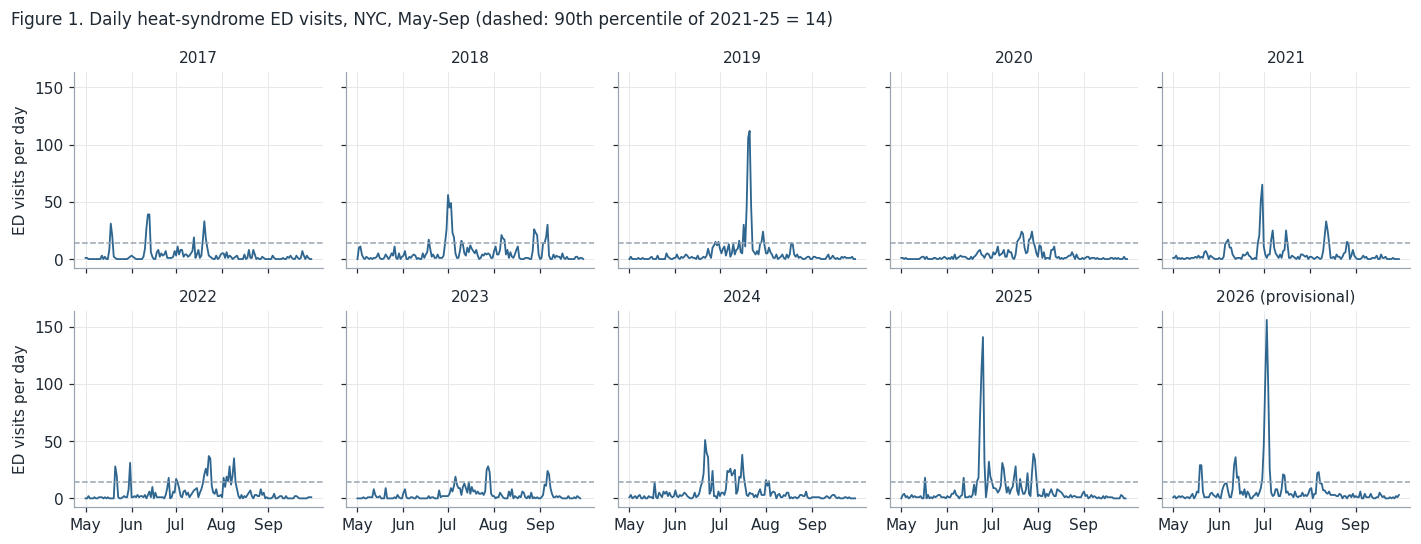

In [32]:
# Figure 1: daily counts by season
fig, axes = plt.subplots(2, 5, figsize=(13, 5), sharex=True, sharey=True)
for ax, (s, g) in zip(axes.flat, ed.groupby("season")):
    x = (g["date"] - pd.Timestamp(f"{s}-05-01")).dt.days
    ax.plot(x, g["N"], color=ACCENT, lw=1.2)
    ax.axhline(KAPPA[0.90], color=MUTED, ls="--", lw=1)
    ax.set_title(f"{s}{' (provisional)' if s == 2026 else ''}", fontsize=10, color=INK)
    ax.set_xticks([0, 31, 61, 92, 123], ["May", "Jun", "Jul", "Aug", "Sep"])
for ax in axes[:, 0]:
    ax.set_ylabel("ED visits per day")
fig.suptitle(f"Figure 1. Daily heat-syndrome ED visits, NYC, May-Sep (dashed: 90th percentile of 2021-25 = {KAPPA[0.90]:g})",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
fig.savefig(FIG / "fig1_daily_counts_by_season.png")
plt.show()

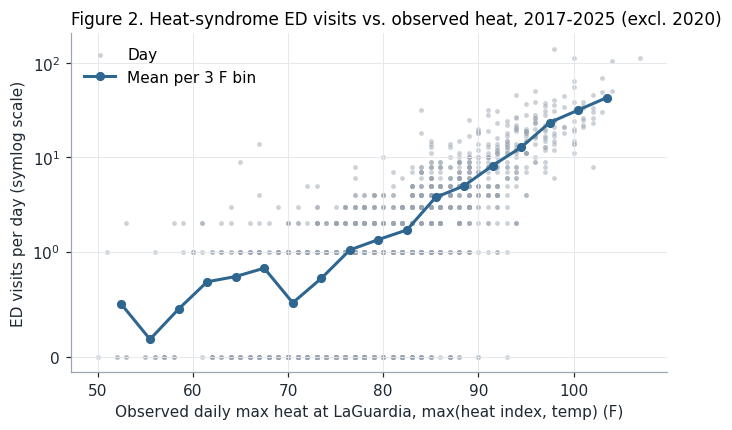

Spearman correlation N vs H: 0.752


In [33]:
# Figure 2: exposure-response, 2017-2025 excluding 2020 (COVID)
er = ed[ed["season"].between(2017, 2025) & (ed["season"] != 2020)].copy()
er["H_bin"] = (er["H"] // 3) * 3
binned = er.groupby("H_bin")["N"].agg(["mean", "size"]).query("size >= 5")
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(er["H"], er["N"], s=10, color=MUTED, alpha=0.5, linewidths=0, label="Day")
ax.plot(binned.index + 1.5, binned["mean"], color=ACCENT, lw=2, marker="o", ms=5, label="Mean per 3 F bin")
ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Observed daily max heat at LaGuardia, max(heat index, temp) (F)")
ax.set_ylabel("ED visits per day (symlog scale)")
ax.set_title("Figure 2. Heat-syndrome ED visits vs. observed heat, 2017-2025 (excl. 2020)", loc="left", fontsize=11)
ax.legend(frameon=False)
fig.savefig(FIG / "fig2_exposure_response.png")
plt.show()
print("Spearman correlation N vs H:", round(er["N"].corr(er["H"], method="spearman"), 3))

## 5. Dependence diagnostics (Dossier Section 9)

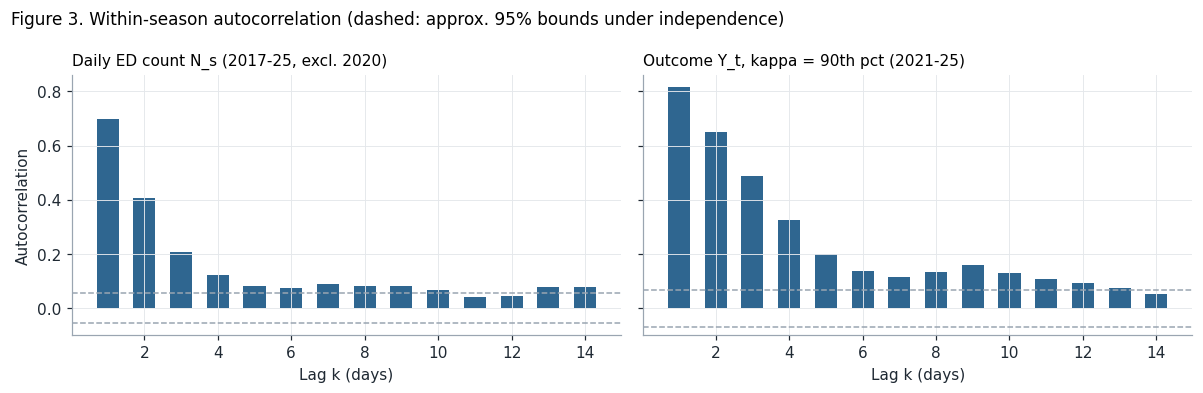

ACF of N_s, lags 1-7: {1: 0.7, 2: 0.41, 3: 0.21, 4: 0.12, 5: 0.08, 6: 0.07, 7: 0.09}
ACF of Y_t, lags 1-7: {1: 0.82, 2: 0.65, 3: 0.49, 4: 0.32, 5: 0.2, 6: 0.14, 7: 0.12}


In [34]:
def within_season_acf(series_by_season, max_lag=14):
    """Average lag-k autocorrelation computed within each season (no cross-season pairs)."""
    out = {}
    for k in range(1, max_lag + 1):
        vals = [x.autocorr(k) for x in series_by_season if len(x.dropna()) > k + 5]
        out[k] = np.nanmean(vals)
    return pd.Series(out)

acf_N = within_season_acf([N[N.index.year == s].dropna().reset_index(drop=True)
                           for s in range(2017, 2026) if s != 2020])
y90 = (d["window_max_N"] >= KAPPA[0.90]).astype(int)
acf_Y = within_season_acf([y90[d.season == s].reset_index(drop=True) for s in MODEL_SEASONS])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, acf, title, n in [(axes[0], acf_N, "Daily ED count N_s (2017-25, excl. 2020)", 153 * 8),
                          (axes[1], acf_Y, "Outcome Y_t, kappa = 90th pct (2021-25)", len(y90))]:
    ax.bar(acf.index, acf.values, color=ACCENT, width=0.6)
    ax.axhline(1.96 / np.sqrt(n), color=MUTED, ls="--", lw=1)
    ax.axhline(-1.96 / np.sqrt(n), color=MUTED, ls="--", lw=1)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("Lag k (days)")
axes[0].set_ylabel("Autocorrelation")
fig.suptitle("Figure 3. Within-season autocorrelation (dashed: approx. 95% bounds under independence)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "fig3_autocorrelation.png")
plt.show()
print("ACF of N_s, lags 1-7:", acf_N.loc[1:7].round(2).to_dict())
print("ACF of Y_t, lags 1-7:", acf_Y.loc[1:7].round(2).to_dict())

In [35]:
# Information on extra rows
same_next = (y90.groupby(d.season).shift(-1) == y90)[y90.groupby(d.season).shift(-1).notna()]
print("P(Y_(t+1) = Y_t):", round(same_next.mean(), 3))

def runs(flags):
    """Count runs of consecutive 1s in a 0/1 series."""
    f = flags.astype(int).values
    return int(((f[1:] == 1) & (f[:-1] == 0)).sum() + (f[0] == 1)) if len(f) else 0

# NYC extreme-heat event: >= 2 consecutive days with heat >= 95 F, or any day >= 100 F
def heat_events(h):
    hot = (h >= 95).astype(int)
    grp = (hot.diff() != 0).cumsum()
    ev = [g for _, g in h[hot == 1].groupby(grp[hot == 1])]
    return sum(1 for g in ev if len(g) >= 2 or g.max() >= 100)

info = pd.DataFrame({
    "decision_rows": d.groupby("season").size(),
    "positive_episodes_Y90": y90.groupby(d.season).apply(runs),
    "heat_events_NYC_def": pd.Series({s: heat_events(H[H.index.year == s].dropna()) for s in range(2021, 2027)}),
})
info.loc["total"] = info.sum()
info

P(Y_(t+1) = Y_t): 0.929


,decision_rows,positive_episodes_Y90,heat_events_NYC_def
2021,143,6,6
2022,143,5,3
2023,140,4,2
2024,143,4,4
2025,110,5,4
2026,143,5,5
total,822,29,24


## 6. Forecast vs. observed heat (Section 10)

      bias    sd   mae    n
lead                       
1    -0.05  3.58  2.72  901
2     0.01  3.76  2.89  895
3    -0.02  4.03  3.08  889
4     0.05  4.50  3.50  883
5     0.55  5.28  4.04  877
6     0.22  5.72  4.42  871
7    -0.01  6.13  4.69  865


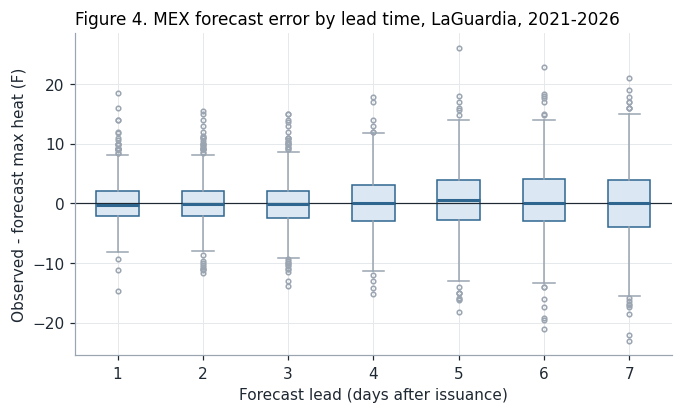

In [40]:
fe = fc[fc["lead"].between(1, 7)].merge(H.rename("H_obs"), left_on="s", right_index=True).dropna(subset=["H_obs"])
fe["error"] = fe["H_obs"] - fe["F"]  # e_{t,s} = H_s - F_{t,s}
fe_tbl = fe.groupby("lead")["error"].agg(bias="mean", sd="std", mae=lambda e: e.abs().mean(), n="size").round(2)
print(fe_tbl.to_string())

fig, ax = plt.subplots(figsize=(7, 3.8))
leads = sorted(fe["lead"].unique())
ax.boxplot([fe.loc[fe["lead"] == k, "error"] for k in leads], positions=leads, widths=0.5,
           patch_artist=True, boxprops=dict(facecolor="#dbe7f3", color=ACCENT), medianprops=dict(color=ACCENT, lw=2),
           whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED), flierprops=dict(marker="o", ms=3, mec=MUTED))
ax.axhline(0, color=INK, lw=0.8)
ax.set_xlabel("Forecast lead (days after issuance)")
ax.set_ylabel("Observed - forecast max heat (F)")
ax.set_title("Figure 4. MEX forecast error by lead time, LaGuardia, 2021-2026", loc="left", fontsize=11)
fig.savefig(FIG / "fig4_forecast_error_by_lead.png")
plt.show()

## 7. Leakage investigation (Section 11)

Same simple logistic model, evaluated three ways. Leave-one-season-out (LOSO) with the threshold κ and the scaling fit on training seasons only is the honest design. A shuffled row-level split and a feature built from future observed heat show how much each leakage pathway would inflate performance.

In [37]:
BASE_FEATURES = ["F_max", "F_mean", "N_lag1", "N_mean3", "H_lag1", "day_of_season"]
dm = d[d["season"].isin(MODEL_SEASONS)].copy()

def logit():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

def loso(features, kappa_q=0.90, model=logit):
    """Leave-one-season-out: kappa and scaling are fit on training seasons only."""
    preds = pd.Series(index=dm.index, dtype=float); ys = pd.Series(index=dm.index, dtype=float)
    for s in MODEL_SEASONS:
        tr, te = dm["season"] != s, dm["season"] == s
        kappa = ed.loc[ed["season"].isin([x for x in MODEL_SEASONS if x != s]), "N"].quantile(kappa_q)
        y = (dm["window_max_N"] >= kappa).astype(int)
        preds[te] = model().fit(dm.loc[tr, features], y[tr]).predict_proba(dm.loc[te, features])[:, 1]
        ys[te] = y[te]
    return ys.astype(int), preds

def shuffled(features, kappa_q=0.90):
    """Random 5-fold row split, kappa from all data: ignores dependence (leaky)."""
    y = (dm["window_max_N"] >= train_daily.quantile(kappa_q)).astype(int)
    preds = pd.Series(index=dm.index, dtype=float)
    for tr, te in KFold(5, shuffle=True, random_state=0).split(dm):
        preds.iloc[te] = logit().fit(dm.iloc[tr][features], y.iloc[tr]).predict_proba(dm.iloc[te][features])[:, 1]
    return y, preds

def scores(y, p):
    return {"AUC": roc_auc_score(y, p), "Brier": brier_score_loss(y, p), "log loss": log_loss(y, p)}

leak = pd.DataFrame({
    "Honest: LOSO, forecast inputs": scores(*loso(BASE_FEATURES)),
    "Leaky: shuffled row split": scores(*shuffled(BASE_FEATURES)),
    "Leaky: + future observed heat": scores(*loso(BASE_FEATURES + ["obs_window_max_H"])),
}).T.round(3)
leak

,AUC,Brier,log loss
"Honest: LOSO, forecast inputs",0.913,0.103,0.335
Leaky: shuffled row split,0.924,0.094,0.311
Leaky: + future observed heat,0.936,0.082,0.291


## 8. Baseline analysis (Sections 12 and 13)

All baselines use LOSO over 2021-2025 with κ = 90th percentile of training-season daily counts, so every score is on unseen seasons. The comparison quantity is the empirical Brier score R̂(f) = (1/m) Σ (y_i − f(x_i, c_i))², with Brier skill score BSS = 1 − R̂(f)/R̂(climatology). Provisional 2026 is scored separately as an out-of-time check.

In [38]:
class Climatology:
    """Predicts the training-season base rate for every day."""
    def fit(self, X, y): self.p = y.mean(); return self
    def predict_proba(self, X): return np.column_stack([1 - np.full(len(X), self.p), np.full(len(X), self.p)])

class AlertRule:
    """Current practice proxy: training-season rate of Y given whether an NWS heat alert is active at t."""
    def fit(self, X, y): self.rate = y.groupby(X["alert_t"]).mean(); return self
    def predict_proba(self, X):
        p = X["alert_t"].map(self.rate).fillna(self.rate.mean()).values
        return np.column_stack([1 - p, p])

candidates = {
    "B0 Climatology (base rate)": (lambda: Climatology(), ["alert_t"]),
    "B1 NWS alert at t": (lambda: AlertRule(), ["alert_t"]),
    "B2 Logistic: forecast max heat only": (logit, ["F_max"]),
    "Preliminary logistic: forecasts + lags + season day": (logit, BASE_FEATURES),
}
rows = {}
for name, (model, feats) in candidates.items():
    y, p = loso(feats, model=model)
    rows[name] = scores(y, p)
base = pd.DataFrame(rows).T
# AUC only measures ranking: climatology has none (constant within each season), and the alert rule's
# ranking is the 0/1 alert indicator itself, so score those two directly rather than on pooled fold rates.
base.loc["B0 Climatology (base rate)", "AUC"] = np.nan
base.loc["B1 NWS alert at t", "AUC"] = roc_auc_score(y, dm.loc[y.index, "alert_t"])
base["Brier skill vs B0"] = 1 - base["Brier"] / base.loc["B0 Climatology (base rate)", "Brier"]
base.round(3)

,AUC,Brier,log loss,Brier skill vs B0
B0 Climatology (base rate),NaN,0.206,0.603,0.000
B1 NWS alert at t,0.508,0.206,0.603,-0.000
B2 Logistic: forecast max heat only,0.863,0.123,0.404,0.402
Preliminary logistic: forecasts + lags + season day,0.913,0.103,0.335,0.498


In [39]:
# Out-of-time check on provisional 2026: train on all of 2021-2025
d26 = d[d["season"] == 2026]
y_tr = (dm["window_max_N"] >= KAPPA[0.90]).astype(int)
y26 = (d26["window_max_N"] >= KAPPA[0.90]).astype(int)
p_clim = np.full(len(d26), y_tr.mean())
p_mod = logit().fit(dm[BASE_FEATURES], y_tr).predict_proba(d26[BASE_FEATURES])[:, 1]
print(f"2026 rows: {len(d26)}, positive rate: {y26.mean():.3f} (2021-25: {y_tr.mean():.3f})")
print(f"Brier 2026 - climatology: {brier_score_loss(y26, p_clim):.3f} | preliminary logistic: {brier_score_loss(y26, p_mod):.3f}")

2026 rows: 143, positive rate: 0.252 (2021-25: 0.292)
Brier 2026 - climatology: 0.190 | preliminary logistic: 0.100
